## Project Overview 
The raw dataset contains approximately 12,000 transaction records and has data quality issues that need to be addressed before analysis. These include missing values in some columns.
This project aims to identify, investigate, and resolve data quality issues systematically. Each cleaning decision will be documented to prepare a reliable dataset for further sales and customer analysis.


## Data Quality Issues Identified

1. Order_Date: Dates appear in different formats. Some entries display only a year and require further inspection to determine whether the full date is missing or the cell formatting shows only the year.
2. Quantity: Some records contain negative quantities. These require investigation to determine whether they represent returns or invalid entries.
3. Discount_Percent: Some records have missing discount percentages.
4. Payment_Method: The same payment method appears with different spellings, capitalization, and formatting.
5. Country: Country names appear as both abbreviations and full names, with inconsistent capitalization.
6. Customer_Rating: Some records have missing ratings. These require review to determine whether the missing values are expected.
7. Shipping_City: Some records have missing shipping city values.




In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv(r"C:\Users\HP Pavilion 15 Touch\OneDrive\Desktop\Ecommerce_Sales_Analysis\Ecommerce_Transactions_Unclean_Data.csv")
df

,Order_ID,Customer_ID,Order_Date,Product_Category,Product_Name,Quantity,Unit_Price_USD,Discount_Percent,Payment_Method,Shipping_City,Country,Order_Status,Customer_Rating
0,ORD011416,CUST00003,2026-04-03,Books,Self-Help Book,3,9.16,5.0,Net Banking,London,UK,Delivered,5.0
1,ORD000974,CUST00269,10-15-2024,Books,Fiction Novel,1,34.24,5.0,NetBanking,Toronto,CA,Shipped,NaN
2,ORD000617,CUST02075,17-Jun-24,Home & Kitchen,Vacuum Cleaner,2,111.95,15.0,DEBIT CARD,Brisbane,Australia,Shipped,NaN
3,ORD006437,CUST02109,16/10/2025,Beauty,Hair Dryer,1,31.84,0.0,Cash on Delivery,Birmingham,U.K.,Delivered,3.0
4,ORD000740,CUST00349,06-Apr-26,Home & Kitchen,Non-Stick Pan,2,72.00,NaN,Credit_Card,Montreal,CA,Delivered,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...
12175,ORD002515,CUST00071,2025-10-17,Home & Kitchen,Storage Organizer,1,106.25,0.0,net banking,Chicago,U.S.A,Delivered,4.0
12176,ORD011799,CUST02583,2024-01-22,Beauty,Sunscreen SPF50,1,24.76,15.0,Pay Pal,Mumbai,india,Delivered,5.0
12177,ORD006638,CUST02113,02-28-2024,Grocery,Olive Oil 1L,1,29.95,10.0,U.P.I,Melbourne,AU,Pending,NaN
12178,ORD002576,CUST00298,2025-06-01,Beauty,Hair Dryer,1,41.41,15.0,Credit_Card,Vancouver,CA,Delivered,NaN


## Task 1: E-Commerce Dataset Cleaning

### 1. Checking Duplicate Records
All columns are compared to identify exact duplicate rows.
Repeated Order IDs alone are not treated as confirmed duplicates.
This check helps prevent repeated transactions from inflating
order counts, quantities, and revenue.

In [3]:
df.duplicated().sum()

print("Rows before cleaning:", len(df))
print("Extra duplicate rows:", df.duplicated().sum())

Rows before cleaning: 12180
Extra duplicate rows: 180


In [4]:
df[df.duplicated(keep=False)].head(10)

,Order_ID,Customer_ID,Order_Date,Product_Category,Product_Name,Quantity,Unit_Price_USD,Discount_Percent,Payment_Method,Shipping_City,Country,Order_Status,Customer_Rating
41,ORD003676,CUST00639,06-Jan-25,Grocery,Almonds 500g,1,11.70,5.0,UPI,Abu Dhabi,U.A.E,Delivered,5.0
50,ORD007171,CUST00040,01-14-2025,Electronics,Webcam,3,189.65,0.0,credit card,Toronto,CA,Delivered,4.0
79,ORD005394,CUST00342,12-Nov-24,Grocery,Green Tea Pack,2,4.34,10.0,DEBIT CARD,Montreal,canada,Delivered,4.0
106,ORD005308,CUST02026,26/08/2024,Grocery,Basmati Rice 5kg,3,20.41,10.0,Credit_Card,Hyderabad,india,Delivered,3.0
108,ORD000283,CUST02279,04-May-26,Beauty,Face Moisturizer,1,9.40,NaN,UPI,Manchester,uk,Delivered,4.0
220,ORD001989,CUST00437,08/04/2025,Home & Kitchen,Vacuum Cleaner,1,179.02,5.0,Debit Card,Birmingham,U.K.,Shipped,NaN
236,ORD008789,CUST00523,08-Jan-26,Beauty,Lipstick,3,37.26,5.0,Credit Card,Bengaluru,india,Delivered,4.0
264,ORD000987,CUST02787,2024-06-15,Home & Kitchen,Air Fryer,1,149.74,15.0,cod,New York,USA,Delivered,3.0
369,ORD006813,CUST01886,2024-12-08,Electronics,Power Bank,3,204.49,10.0,U.P.I,Melbourne,australia,Delivered,NaN
376,ORD005186,CUST01256,02-25-2025,Electronics,Gaming Mouse,1,161.45,10.0,debit card,Munich,Germany,Shipped,NaN


In [5]:
# for verify
df[df["Order_ID"] == "ORD003676"]

,Order_ID,Customer_ID,Order_Date,Product_Category,Product_Name,Quantity,Unit_Price_USD,Discount_Percent,Payment_Method,Shipping_City,Country,Order_Status,Customer_Rating
41,ORD003676,CUST00639,06-Jan-25,Grocery,Almonds 500g,1,11.7,5.0,UPI,Abu Dhabi,U.A.E,Delivered,5.0
2040,ORD003676,CUST00639,06-Jan-25,Grocery,Almonds 500g,1,11.7,5.0,UPI,Abu Dhabi,U.A.E,Delivered,5.0


### Duplicate Removal Result
The dataset contained 12,180 rows, including 180 extra exact
duplicate rows. These duplicates were removed while retaining
the first occurrence of each record. After cleaning, 12,000 rows
remained, with no exact duplicates.

In [6]:
df_clean = df.drop_duplicates().copy()

print("Rows after cleaning:", len(df_clean))
print("Remaining duplicates:", df_clean.duplicated().sum())

Rows after cleaning: 12000
Remaining duplicates: 0


### 2. Missing Value Check
Missing values were counted in each column after removing duplicates.

In [7]:
df_clean.isnull().sum()

Order_ID               0
Customer_ID            0
Order_Date             0
Product_Category       0
Product_Name           0
Quantity               0
Unit_Price_USD         0
Discount_Percent     722
Payment_Method         0
Shipping_City        494
Country                0
Order_Status           0
Customer_Rating     6056
dtype: int64

In [8]:
(df_clean.isnull().mean() * 100).round(2)

Order_ID             0.00
Customer_ID          0.00
Order_Date           0.00
Product_Category     0.00
Product_Name         0.00
Quantity             0.00
Unit_Price_USD       0.00
Discount_Percent     6.02
Payment_Method       0.00
Shipping_City        4.12
Country              0.00
Order_Status         0.00
Customer_Rating     50.47
dtype: float64

### 3. Handling Missing Shipping Cities
Shipping_City had 494 missing values (4.12%). These were filled
with "Unknown" because the actual city information was unavailable.
No rows were removed. Verification confirmed zero remaining
null values in this column.

In [9]:
df_clean["Shipping_City"] = df_clean["Shipping_City"].fillna("Unknown")

# check one again
df_clean["Shipping_City"].isnull().sum()

np.int64(0)

### 4. Handling Missing Customer Ratings
Customer_Rating had 6,056 missing values (50.47%).
All non-delivered order statuses had missing ratings.
An additional 634 delivered orders had no recorded rating.

Missing ratings were retained because they represent unavailable
feedback. Filling them with zero or the mean would introduce
unsupported values. No rows were removed.

In [10]:
df_clean.groupby("Order_Status")["Customer_Rating"].agg(
    ["size", "count"]
)

,size,count
Order_Status,,
Cancelled,1196,0
Delivered,6578,5944
Pending,1395,0
Returned,1015,0
Shipped,1816,0


In [11]:
df_clean["Discount_Percent"].value_counts(dropna=False)

Discount_Percent
0.0     4033
10.0    2253
5.0     2228
15.0    1619
20.0     826
NaN      722
25.0     319
Name: count, dtype: int64

### 5. Handling Missing Discounts
Discount_Percent had 722 missing values (6.02%).
These were retained because a missing discount does not
necessarily mean zero discount. A Discount_Missing flag
was added to identify these records. No rows were removed.

In [12]:
df_clean["Discount_Missing"] = df_clean["Discount_Percent"].isnull()

df_clean["Discount_Missing"].sum()

np.int64(722)

In [13]:
df_clean["Payment_Method"].value_counts()

Payment_Method
paypal              701
net banking         693
PayPal              689
Net Banking         682
UPI                 678
DEBIT CARD          671
NetBanking          650
Pay Pal             643
U.P.I               638
debit card          623
Debit Card          616
upi                 615
COD                 534
CREDIT CARD         529
cash on delivery    520
cod                 515
Credit_Card         506
Cash on Delivery    501
credit card         499
Credit Card         497
Name: count, dtype: int64

### 6. Standardizing Payment Methods
Payment_Method contained 20 labels due to differences in
spelling, capitalization, punctuation, and spacing. These
were standardized into six payment methods: PayPal,
Net Banking, UPI, Debit Card, Cash on Delivery, and Credit Card.
This ensures that equivalent methods are grouped correctly.

In [14]:
payment_map = {
    "paypal": "PayPal",
    "Pay Pal": "PayPal",
    "net banking": "Net Banking",
    "NetBanking": "Net Banking",
    "upi": "UPI",
    "U.P.I": "UPI",
    "DEBIT CARD": "Debit Card",
    "debit card": "Debit Card",
    "COD": "Cash on Delivery",
    "cod": "Cash on Delivery",
    "cash on delivery": "Cash on Delivery",
    "CREDIT CARD": "Credit Card",
    "Credit_Card": "Credit Card",
    "credit card": "Credit Card"
}

df_clean["Payment_Method"] = (
    df_clean["Payment_Method"].str.strip().replace(payment_map)
)

df_clean["Payment_Method"].value_counts()

Payment_Method
Cash on Delivery    2070
PayPal              2033
Credit Card         2031
Net Banking         2025
UPI                 1931
Debit Card          1910
Name: count, dtype: int64

In [15]:
df_clean["Country"].value_counts()

Country
UAE               593
australia         591
DE                587
Germany           581
germany           579
uae               577
india             576
Australia         576
IN                575
U.A.E             572
canada            563
AU                540
CA                539
India             539
Canada            533
uk                455
U.K.              444
United Kingdom    439
UK                430
usa               366
USA               361
United States     341
US                335
U.S.A             308
Name: count, dtype: int64

### 7. Standardizing Country Names
The Country column contained 24 labels due to abbreviations,
punctuation, and differences in capitalization. These were
standardized into seven full country names so that records
from the same country are grouped correctly.

In [16]:
country_map = {
    "UAE": "United Arab Emirates",
    "uae": "United Arab Emirates",
    "U.A.E": "United Arab Emirates",
    "australia": "Australia",
    "AU": "Australia",
    "DE": "Germany",
    "germany": "Germany",
    "india": "India",
    "IN": "India",
    "canada": "Canada",
    "CA": "Canada",
    "uk": "United Kingdom",
    "U.K.": "United Kingdom",
    "UK": "United Kingdom",
    "usa": "United States",
    "USA": "United States",
    "US": "United States",
    "U.S.A": "United States"
}

df_clean["Country"] = (
    df_clean["Country"].str.strip().replace(country_map)
)

df_clean["Country"].value_counts()

Country
United Kingdom          1768
Germany                 1747
United Arab Emirates    1742
United States           1711
Australia               1707
India                   1690
Canada                  1635
Name: count, dtype: int64

### 8. Inspecting Order Dates
The data type and date values were inspected before conversion
to identify mixed formats and potentially incomplete dates.

In [17]:
# check data type of Order_Date
print(df_clean["Order_Date"].dtype)

# show first 20 Dates
df_clean["Order_Date"].head(20)

object


0     2026-04-03
1     10-15-2024
2      17-Jun-24
3     16/10/2025
4      06-Apr-26
5     11-09-2024
6     21/03/2026
7     10/07/2024
8     19/08/2025
9     07-14-2025
10    06-05-2024
11     09-Jun-25
12     11-Jun-25
13    12-09-2024
14    12-23-2025
15     15-Jul-25
16    2025-11-05
17     11-Nov-25
18    04/04/2025
19    04-16-2026
Name: Order_Date, dtype: object

### 8.1  Standardizing Order Dates
Order_Date contained five different text formats. These were
converted into a consistent datetime type using explicit formats.

Month-day-year was assumed for month-first hyphenated dates,
and day-month-year for day-first slash-separated dates.

In [18]:
dates = df_clean["Order_Date"].str.strip()

for separator in ["-", "/"]:
    parts = dates.str.extract(
        rf"^(\d{{2}}){separator}(\d{{2}}){separator}(\d{{4}})$"
    )

    print(
        separator,
        "First part > 12:", (parts[0].astype(float) > 12).sum(),
        "Second part > 12:", (parts[1].astype(float) > 12).sum()
    )

- First part > 12: 0 Second part > 12: 1467
/ First part > 12: 1447 Second part > 12: 0


In [19]:
dates = df_clean["Order_Date"].str.strip()

formats = [
    "%Y-%m-%d",
    "%m-%d-%Y",
    "%d %b %Y",
    "%d/%m/%Y",
    "%Y/%m/%d"
]

parsed_dates = pd.Series(pd.NaT, index=df_clean.index)

for fmt in formats:
    converted = pd.to_datetime(dates, format=fmt, errors="coerce")
    parsed_dates = parsed_dates.fillna(converted)

print("Unparsed dates:", parsed_dates.isna().sum())

Unparsed dates: 2339


Date patterns suggest month-day-year for month-first hyphenated
dates and day-month-year for slash-separated dates. These rules
were applied consistently, including to ambiguous dates.
Each observed format was parsed separately, and unsuccessful
conversions were checked before replacing the original column.

In [20]:
df_clean["Order_Date"] = parsed_dates

print(df_clean["Order_Date"].dtype)
df_clean["Order_Date"].head()

datetime64[ns]


0   2026-04-03
1   2024-10-15
2          NaT
3   2025-10-16
4          NaT
Name: Order_Date, dtype: datetime64[ns]

In [21]:
df_clean["Quantity"].value_counts().sort_index()

Quantity
-1      96
 0      90
 1    5258
 2    2957
 3    1811
 4    1224
 5     564
Name: count, dtype: int64

### 9. Investigating Non-Positive Quantities
Quantity contained 96 negative values and 90 zero values.
Together, these represent 186 records (1.55% of the dataset).
No decimal quantities were found. These records were examined
by order status before deciding how to handle them.

In [22]:
pd.crosstab(
    df_clean["Order_Status"],
    df_clean["Quantity"]
)

Quantity,-1,0,1,2,3,4,5
Order_Status,,,,,,,
Cancelled,10,8,536,294,174,118,56
Delivered,50,56,2849,1630,985,691,317
Pending,14,11,606,335,230,130,69
Returned,9,9,464,248,141,101,43
Shipped,13,6,803,450,281,184,79


In [23]:
df_clean["Invalid_Quantity"] = df_clean["Quantity"] <= 0

df_clean["Invalid_Quantity"].sum()

np.int64(186)

### 9. Handling Non-Positive Quantities
Quantity contained 96 negative values and 90 zero values,
affecting 186 records (1.55%). These occurred across all order
statuses, so negative quantities could not be assumed to
represent returns.

The original values were retained, and an Invalid_Quantity
flag was added. These records will be excluded from sales
quantity and revenue calculations. No quantities were imputed,
and no rows were removed.

### 10. Checking Unit Prices
Unit_Price_USD was checked for missing values, zero or negative
prices, and its data type before revenue calculations.

In [24]:
print("Missing prices:", df_clean["Unit_Price_USD"].isnull().sum())
print("Zero or negative prices:", (df_clean["Unit_Price_USD"] <= 0).sum())
print("Data type:", df_clean["Unit_Price_USD"].dtype)

Missing prices: 0
Zero or negative prices: 0
Data type: float64


### 10.1 Validating Unit Prices
Unit_Price_USD had no missing, zero, or negative values.
The column was stored as float64, confirming a numeric
data type. No corrections were required for these checks.

In [25]:
print(df_clean["Product_Category"].unique())
print(df_clean["Order_Status"].unique())

['Books' 'Home & Kitchen' 'Beauty' 'Fashion' 'Sports' 'Toys' 'Electronics'
 'Grocery']
['Delivered' 'Shipped' 'Cancelled' 'Returned' 'Pending']


### 11. Checking Category and Order Status Labels
Product_Category contained eight distinct categories, and
Order_Status contained five distinct statuses. No spelling
or capitalization inconsistencies were observed in these labels.
No corrections were required.

In [26]:
for col in ["Product_Category", "Product_Name", "Order_Status"]:
    count = (df_clean[col] != df_clean[col].str.strip()).sum()
    print(col, "extra-space rows:", count)

Product_Category extra-space rows: 0
Product_Name extra-space rows: 0
Order_Status extra-space rows: 0


### 12. Checking Extra Spaces
Product_Category, Product_Name, and Order_Status were checked
for leading and trailing spaces. No such spaces were found,
so no corrections were required.

In [27]:
print("Ratings outside 1–5:",
      ((df_clean["Customer_Rating"] < 1) |
       (df_clean["Customer_Rating"] > 5)).sum())

print("Discounts outside 0–100:",
      ((df_clean["Discount_Percent"] < 0) |
       (df_clean["Discount_Percent"] > 100)).sum())

Ratings outside 1–5: 0
Discounts outside 0–100: 0


### 13. Validating Rating and Discount Ranges
No non-missing customer ratings were outside the range of 1–5.
No non-missing discount percentages were outside the range
of 0–100. No range corrections were required.

In [28]:
print("Invalid Order IDs:",
      (~df_clean["Order_ID"].str.fullmatch(r"ORD\d{6}", na=False)).sum())

print("Invalid Customer IDs:",
      (~df_clean["Customer_ID"].str.fullmatch(r"CUST\d{5}", na=False)).sum())

Invalid Order IDs: 0
Invalid Customer IDs: 0


### 14. Validating Identifier Formats
All Order_ID values matched ORD followed by six digits.
All Customer_ID values matched CUST followed by five digits.
No invalid identifier formats were found.

In [29]:
print("Unique product names:", df_clean["Product_Name"].nunique())

sorted(df_clean["Product_Name"].unique())

Unique product names: 46


['Action Figure',
 'Air Fryer',
 'Almonds 500g',
 'Backpack',
 'Basmati Rice 5kg',
 'Blender',
 'Bluetooth Speaker',
 'Building Blocks Set',
 'Ceramic Mug Set',
 'Cookbook',
 'Cotton T-Shirt',
 'Cricket Bat',
 'Cycling Helmet',
 'Denim Jacket',
 'Dumbbell Set',
 'Face Moisturizer',
 'Fiction Novel',
 'Football',
 'Formal Shirt',
 'Gaming Mouse',
 'Green Tea Pack',
 'Hair Dryer',
 'Hoodie',
 'Kids Storybook',
 'LED Desk Lamp',
 'Laptop Stand',
 'Leather Wallet',
 'Lipstick',
 'Non-Stick Pan',
 'Olive Oil 1L',
 'Perfume',
 'Power Bank',
 'Puzzle 1000pc',
 'Remote Control Car',
 'Running Shoes',
 'Self-Help Book',
 'Shampoo',
 'Smartwatch',
 'Storage Organizer',
 'Sunglasses',
 'Sunscreen SPF50',
 'USB-C Cable',
 'Vacuum Cleaner',
 'Webcam',
 'Wireless Earbuds',
 'Yoga Mat']

### 15. Reviewing Product Names
The 46 unique product names were reviewed. No obvious spelling
or capitalization inconsistencies were found, so no changes
were made.

In [30]:
product_categories = df_clean.groupby("Product_Name")[
    "Product_Category"
].nunique()

product_categories[product_categories > 1]

Series([], Name: Product_Category, dtype: int64)

### 16. Checking Product–Category Consistency
Each product was associated with only one category.
No products appeared under multiple categories, so no
corrections were required.

In [31]:
sorted(df_clean["Shipping_City"].unique())

['Abu Dhabi',
 'Bengaluru',
 'Berlin',
 'Birmingham',
 'Brisbane',
 'Chicago',
 'Delhi',
 'Dubai',
 'Hamburg',
 'Houston',
 'Hyderabad',
 'London',
 'Los Angeles',
 'Manchester',
 'Melbourne',
 'Montreal',
 'Mumbai',
 'Munich',
 'New York',
 'Sydney',
 'Toronto',
 'Unknown',
 'Vancouver']

### 17. Reviewing Shipping City Labels
Shipping city labels were reviewed. No obvious spelling or
capitalization inconsistencies were found. "Unknown" represents
records where the original shipping city was missing.

In [32]:
city_country = (
    df_clean[df_clean["Shipping_City"] != "Unknown"]
    .groupby("Shipping_City")["Country"]
    .nunique()
)

city_country[city_country > 1]

Series([], Name: Country, dtype: int64)

### 18. Checking City–Country Consistency
Each known shipping city was associated with only one country.
Records labelled "Unknown" were excluded from this check.
No cities were linked to multiple countries.

In [33]:
print("Final rows:", len(df_clean))
print("Final columns:", df_clean.shape[1])
print("Remaining duplicates:", df_clean.duplicated().sum())

df_clean.isnull().sum()

Final rows: 12000
Final columns: 15
Remaining duplicates: 0


Order_ID               0
Customer_ID            0
Order_Date          2339
Product_Category       0
Product_Name           0
Quantity               0
Unit_Price_USD         0
Discount_Percent     722
Payment_Method         0
Shipping_City          0
Country                0
Order_Status           0
Customer_Rating     6056
Discount_Missing       0
Invalid_Quantity       0
dtype: int64

In [34]:
df_clean.to_csv("ecommerce_cleaned.csv", index=False)

## Final Cleaning Summary

- Original dataset: 12,180 rows and 13 columns.
- Removed 180 extra exact duplicate rows.
- Final dataset: 12,000 rows and 15 columns, with zero exact duplicates.
- Filled 494 missing shipping cities with "Unknown".
- Standardized payment methods into six labels and countries into seven names.
- Converted Order_Date from text to datetime.
- Retained 722 missing discounts and added a Discount_Missing flag.
- Retained 6,056 missing customer ratings without imputation.
- Flagged 186 non-positive quantities without changing their values.
- Saved the dataset as ecommerce_cleaned.csv.

## Limitations

Missing discounts and ratings remain unavailable.
Non-positive quantities require further clarification and will
be excluded from quantity and revenue calculations.
Ambiguous numeric dates were interpreted using the documented
date-format assumptions.

## Task 2: Sales Data Analysis

In [35]:
df_clean["Total_Amount"] = (
    df_clean["Quantity"]
    * df_clean["Unit_Price_USD"]
    * (1 - df_clean["Discount_Percent"] / 100)
).round(2)

df_clean[["Quantity", "Unit_Price_USD", "Discount_Percent", "Total_Amount"]].head()

In [36]:
sales_df = df_clean[
    (df_clean["Order_Status"] == "Delivered")
    & (~df_clean["Invalid_Quantity"])
    & (df_clean["Total_Amount"].notna())
].copy()

print("Eligible sales records:", len(sales_df))

Eligible sales records: 6082


In [37]:
total_revenue = sales_df["Total_Amount"].sum()

print(f"Total Revenue (USD): ${total_revenue:,.2f}")

Total Revenue (USD): $719,962.24


### KPI 1: Total Revenue

Total Revenue = Sum of Total_Amount for eligible sales records.

Revenue was $719,962.24 from 6,082 delivered records with
positive quantities and available discounts. Amounts include
discounts but exclude tax and shipping.

Records with missing discounts or non-positive quantities were
excluded, so this figure does not cover all delivered orders.

### KPI Summary

| KPI | Result |
|---|---:|
| Revenue from Eligible Orders | $719,962.24 |
| Total Eligible Orders | 6,082 |
| Average Order Value | $118.38 |
| Total Units Sold | 12,582 |
| Top Category by Revenue | Electronics |
| Top Product by Revenue | Smartwatch |

These KPIs use delivered orders with positive quantities and
available discounts. Average Order Value is revenue divided
by the number of unique eligible orders.

In [38]:
total_orders = sales_df["Order_ID"].nunique()
print("Total Eligible Orders:", total_orders)

Total Eligible Orders: 6082


### KPI 2: Total Eligible Orders

Total Eligible Orders = Number of unique Order_ID values
in the eligible sales dataset.

There were 6,082 eligible orders. Only delivered orders with
positive quantities and available discounts were included.
This count does not represent all orders in the dataset.

In [39]:
average_order_value = total_revenue / total_orders
print(f"Average Order Value: ${average_order_value:,.2f}")

Average Order Value: $118.38


### KPI 3: Average Order Value

Average Order Value = Revenue from Eligible Orders ÷ Total Eligible Orders

$719,962.24 ÷ 6,082 = $118.38

Eligible delivered orders had an average value of $118.38
after discounts, excluding tax and shipping.

In [40]:
total_units = sales_df["Quantity"].sum()
print("Total Units Sold:", total_units)

Total Units Sold: 12582


### KPI 4: Total Units Sold

Total Units Sold = Sum of Quantity in the eligible sales dataset.

A total of 12,582 units were sold across the 6,082 eligible
delivered orders. Orders with non-positive quantities or
missing discounts were excluded from this KPI.

In [41]:
category_revenue = sales_df.groupby("Product_Category")["Total_Amount"].sum()
print("Top Category by Revenue:", category_revenue.idxmax())

Top Category by Revenue: Electronics


### KPI 5: Top Category by Revenue

Revenue was summed by Product_Category for eligible sales records.

Electronics generated the highest revenue among all categories.
This ranking measures revenue contribution, not the number
of units sold.

In [42]:
product_revenue = sales_df.groupby("Product_Name")["Total_Amount"].sum()
print("Top Product by Revenue:", product_revenue.idxmax())

Top Product by Revenue: Smartwatch


### KPI 6: Top Product by Revenue

Revenue was summed by Product_Name for eligible sales records.

Smartwatch generated the highest revenue among all products.
This ranking measures revenue contribution, not units sold.

In [43]:
monthly_sales = sales_df.groupby(
    sales_df["Order_Date"].dt.to_period("M")
)["Total_Amount"].sum().sort_index()

print(monthly_sales)
print("\nHighest revenue month:", monthly_sales.idxmax())
print(f"Highest monthly revenue: ${monthly_sales.max():,.2f}")

Order_Date
2024-01    18678.21
2024-02    21071.18
2024-03    19518.92
2024-04    23796.95
2024-05    18567.64
2024-06    17147.97
2024-07    19627.57
2024-08    19739.03
2024-09    21107.86
2024-10    20054.11
2024-11    15546.69
2024-12    21848.54
2025-01    20943.72
2025-02    17106.52
2025-03    21109.81
2025-04    18475.26
2025-05    20425.12
2025-06    20844.53
2025-07    17378.02
2025-08    21340.73
2025-09    17119.65
2025-10    22259.83
2025-11    21382.68
2025-12    17713.32
2026-01    15802.09
2026-02    16067.88
2026-03    18793.42
2026-04    16673.61
2026-05    18241.64
2026-06    20077.59
Freq: M, Name: Total_Amount, dtype: float64

Highest revenue month: 2024-04
Highest monthly revenue: $23,796.95


### Monthly Sales Trend

Monthly revenue from eligible orders fluctuated between
January 2024 and June 2026, without a consistent upward trend.

April 2024 recorded the highest revenue at $28,232.78.
November 2024 recorded the lowest revenue at $20,466.64.

These changes suggest variation in monthly sales performance.
Order volume and product mix should be examined to understand
the differences; this analysis does not establish their causes.

In [44]:
customer_sales = sales_df.groupby("Customer_ID").agg(
    Orders=("Order_ID", "nunique"),
    Revenue=("Total_Amount", "sum")
)

repeat_customers = customer_sales[customer_sales["Orders"] > 1]

print("Unique customers:", len(customer_sales))
print("Repeat customers:", len(repeat_customers))

repeat_share = repeat_customers["Revenue"].sum() / total_revenue * 100
print(f"Repeat-customer revenue share: {repeat_share:.2f}%")

Unique customers: 2883
Repeat customers: 1823
Repeat-customer revenue share: 82.94%


### Customer Insights

The eligible sales dataset contained 2,883 unique customers.
Of these, 1,823 placed more than one eligible order.

Repeat customers contributed 82.94% of eligible revenue,
showing that most revenue in this subset came from customers
with multiple purchases.

Customer retention could be explored as a business priority.
Repeat status is based only on eligible orders in this dataset,
not the customer's complete purchase history.

## Task 3: Visualization Challenge


All charts use eligible delivered orders with positive
quantities and available discounts.

### 1. Revenue by Category — Bar Chart

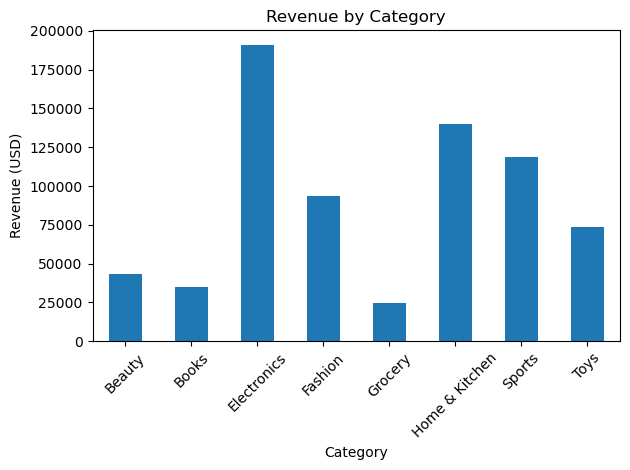

In [45]:
category_revenue.plot(kind="bar")

plt.title("Revenue by Category")
plt.xlabel("Category")
plt.ylabel("Revenue (USD)")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig("category_revenue.png")
plt.show()

### Observation
The bar chart compares revenue across product categories.
Electronics generated the highest revenue among eligible
delivered orders.


### 2. Monthly Revenue Trend — Line Chart

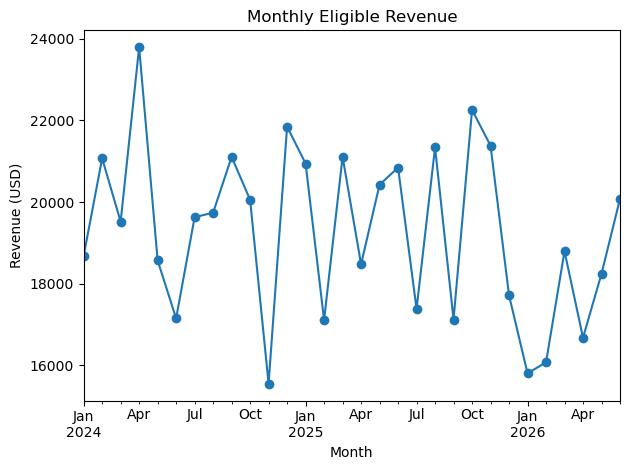

In [46]:
monthly_sales.plot(kind="line", marker="o")

plt.title("Monthly Eligible Revenue")
plt.xlabel("Month")
plt.ylabel("Revenue (USD)")
plt.tight_layout()

plt.savefig("monthly_revenue.png")
plt.show()

### Obeservation
The line chart shows monthly eligible revenue from January 2024
April 2024 recorded the highest eligible revenue at $28,232.78,
while November 2024 recorded the lowest at $20,466.64.
Revenue fluctuated without a consistent upward trend.
The chart does not establish the causes of these changes.


### 3. Order Share by Payment Method — Pie Chart

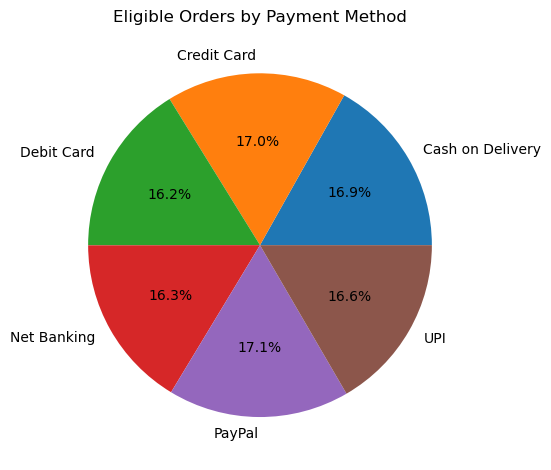

Payment_Method
Cash on Delivery    1025
Credit Card         1032
Debit Card           985
Net Banking          993
PayPal              1037
UPI                 1010
Name: Order_ID, dtype: int64


In [47]:
payment_orders = sales_df.groupby("Payment_Method")["Order_ID"].nunique()

payment_orders.plot(kind="pie", autopct="%1.1f%%")

plt.title("Eligible Orders by Payment Method")
plt.ylabel("")
plt.tight_layout()

plt.savefig("payment_share.png")
plt.show()

print(payment_orders)

### Observation
PayPal had the largest share of eligible orders, with 1,037
orders (17.05%). Debit Card had the smallest share, with
985 orders (16.20%).

All six payment methods had similar shares, ranging from
16.20% to 17.05%; no single method strongly dominated.
These percentages represent order counts, not revenue.



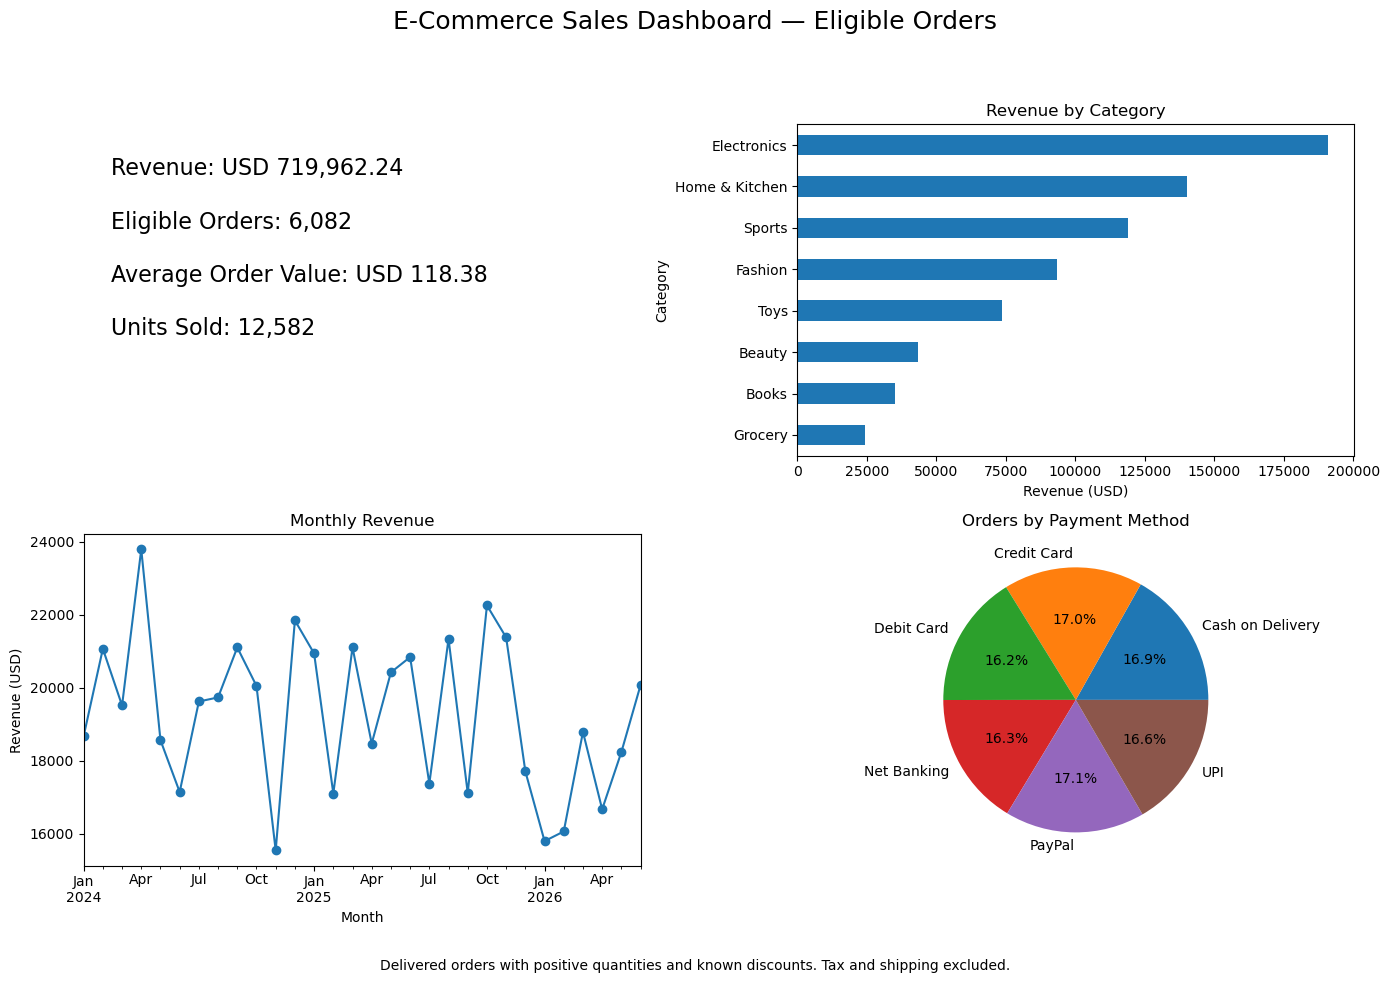

In [48]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

fig.suptitle("E-Commerce Sales Dashboard — Eligible Orders", fontsize=18)

# KPI summary
axes[0, 0].axis("off")
axes[0, 0].text(
    0.05, 0.9,
    f"Revenue: USD {total_revenue:,.2f}\n\n"
    f"Eligible Orders: {total_orders:,}\n\n"
    f"Average Order Value: USD {average_order_value:,.2f}\n\n"
    f"Units Sold: {total_units:,}",
    fontsize=16, va="top"
)

# Category chart
category_revenue.sort_values().plot(
    kind="barh", ax=axes[0, 1]
)
axes[0, 1].set_title("Revenue by Category")
axes[0, 1].set_xlabel("Revenue (USD)")
axes[0, 1].set_ylabel("Category")

# Monthly trend
monthly_sales.plot(
    kind="line", marker="o", ax=axes[1, 0]
)
axes[1, 0].set_title("Monthly Revenue")
axes[1, 0].set_xlabel("Month")
axes[1, 0].set_ylabel("Revenue (USD)")

# Payment share
payment_orders.plot(
    kind="pie", autopct="%1.1f%%", ax=axes[1, 1]
)
axes[1, 1].set_title("Orders by Payment Method")
axes[1, 1].set_ylabel("")

fig.text(
    0.5, 0.02,
    "Delivered orders with positive quantities and known discounts. "
    "Tax and shipping excluded.",
    ha="center", fontsize=10
)

plt.tight_layout(rect=[0, 0.05, 1, 0.94])
plt.savefig("dashboard_mockup.png", dpi=150)
plt.show()

## Key Findings

1. Eligible revenue was USD 719,962.24 across 6,082 delivered orders.
2. Average eligible order value was USD 118.38.
3. These orders contained 12,582 units.
4. Electronics generated the highest category revenue.
5. Smartwatch generated the highest product revenue.
6. April 2024 had the highest monthly revenue (USD 28,232.78),
   while November 2024 had the lowest (USD 20,466.64).
7. Repeat customers contributed 82.94% of eligible revenue.
8. Payment methods had similar order shares, with PayPal
   slightly ahead at 17.05%.

## Recommendations

- Explore retention initiatives, given repeat customers'
  large contribution to eligible revenue.
- Review Electronics and Smartwatch inventory and profitability
  before making stocking decisions.
- Investigate order volume and product mix behind monthly changes.
- Recover missing discounts and clarify non-positive quantities
  to improve revenue coverage.

## Limitations

The dataset is synthetic. Sales KPIs cover only delivered orders
with positive quantities and known discounts. Of 6,578 delivered
records, 6,082 were eligible (92.46%); 496 were excluded.
Revenue excludes tax and shipping. Repeat-customer status is
based only on eligible orders. Ambiguous dates were interpreted
using the documented format assumptions.



In [51]:
df_clean.to_csv("ecommerce_analysis_data.csv", index=False)